# Named-Entity Recognition with Robert Louis Stevenson's Letters

[![](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gpizzorno/understanding-ai/blob/main/code/ner_pipeline.ipynb)

This notebook accompanies [Unit 3: Programmatic Approaches](https://gpizzorno.github.io/understanding-ai/unit_3/index.html). You'll use a pre-trained Named-Entity Recognition (NER) model to extract people, places, and organizations from 462 letters by Robert Louis Stevenson (RLS), written between 1863 and 1894. Then you'll evaluate how well the model did against human annotations, and compare it with a second model.

You don't need to write code from scratch. Read each cell before you run it, and if something is unclear, ask an LLM to explain it.

## Contents

1. [Setup and Data Exploration](#section-1-setup-and-data-exploration)
2. [Loading a Pre-Trained NER Model](#section-2-loading-a-pre-trained-ner-model)
3. [Processing the Full Corpus](#section-3-processing-the-full-corpus)
4. [Exploring the Results](#section-4-exploring-the-results)
5. [Entity Resolution](#section-5-entity-resolution)
6. [Network Analysis](#section-6-network-analysis)
7. [Timeline Analysis](#section-7-timeline-analysis)
8. [Mapping Places](#section-8-mapping-places)
9. [Evaluation with Human Annotations](#section-9-evaluation-with-human-annotations)
10. [Comparison with Another Model](#section-10-comparison-with-another-model)

## Section 1: Setup and Data Exploration

If you are running this notebook in Google Colab, the first cell downloads a copy of the repository so the notebook can find the data. If you are running the notebook in Jupyter locally, the cell does nothing.

In [1]:
# in Google Colab, download this repository so that the notebook can find the data
# when running locally, this cell does nothing
import os
import subprocess
import sys
from pathlib import Path

base_path = Path('../data/letters')
repository = 'https://github.com/gpizzorno/understanding-ai.git'

if 'google.colab' in sys.modules and not base_path.exists():
    if not Path('understanding-ai').exists():
        subprocess.run(['git', 'clone', '--depth', '1', repository], check=True)
    os.chdir('understanding-ai/code')

In [ ]:
import re
import warnings
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import seaborn as sns
from huggingface_hub.utils import logging as hub_logging
from transformers import pipeline
from transformers.utils import logging as transformers_logging

# data paths
DATA_DIR = Path('../data')
OUTPUT_DIR = Path('../outputs')
OUTPUT_DIR.mkdir(exist_ok=True)

# plotting style for charts
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

warnings.filterwarnings('ignore')

# hide progress bars, loading reports, and notices, which clutter the output
transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()
hub_logging.set_verbosity_error()

In [3]:
# load the metadata
metadata = pd.read_csv(DATA_DIR / 'letters_metadata.csv')

print(f'Total letters in corpus: {len(metadata)}')
print('\nFirst few rows:')
metadata.head()

Total letters in corpus: 462

First few rows:


,addressee,date,month,day,year,file_name
0,SPRING GROVE SCHOOL,NOVEMBER 12 1863,NOVEMBER,12.0,1863.0,wikisource_vol1_ch1_letter1.txt
1,CHARLES BAXTER,APRIL 9 1872,APRIL,9.0,1872.0,wikisource_vol1_ch1_letter10.txt
2,MRS. THOMAS STEVENSON,JULY 25 1872,JULY,25.0,1872.0,wikisource_vol1_ch1_letter11.txt
3,MRS. THOMAS STEVENSON,JULY 29 1872,JULY,29.0,1872.0,wikisource_vol1_ch1_letter12.txt
4,MRS. THOMAS STEVENSON,AUGUST 2 1872,AUGUST,2.0,1872.0,wikisource_vol1_ch1_letter13.txt


In [4]:
# read a sample letter
sample_file = DATA_DIR / 'letters' / 'wikisource_vol1_ch3_letter14.txt'

with open(sample_file, encoding='utf-8') as file:
    sample_text = file.read()

print('Sample letter:')
print('=' * 80)
print(sample_text)
print('=' * 80)

Sample letter:
Letter: TO SIDNEY COLVIN

[EDINBURGH, AUGUST 1877.]
MY DEAR COLVIN, - I'm to be whipped away to-morrow to Penzance, where at the post-office a letter will find me glad and grateful. I am well, but somewhat tired out with overwork. I have only been home a fortnight this morning, and I have already written to the tune of forty-five CORNHILL pages and upwards. The most of it was only very laborious re-casting and re-modelling, it is true; but it took it out of me famously, all the same.
TEMPLE BAR appears to like my 'Villon,' so I may count on another market there in the future, I hope. At least, I am going to put it to the proof at once, and send another story, 'The Sire de Maletroit's Mousetrap': a true novel, in the old sense; all unities preserved moreover, if that's anything, and I believe with some little merits; not so CLEVER perhaps as the last, but sounder and more natural.
My 'Villon' is out this month; I should so much like to know what you think of it. Stephen h

## Section 2: Loading a Pre-Trained NER Model

We'll use the Hugging Face `transformers` library to load a pre-trained NER model. We're using [`Davlan/bert-base-multilingual-cased-ner-hrl`](https://huggingface.co/Davlan/bert-base-multilingual-cased-ner-hrl), which recognizes:
- PER (Person)
- ORG (Organization)
- LOC (Location)

The model can read at most 512 tokens at a time (roughly 370 words), and about half of the letters are longer than that. The `stride` setting makes the pipeline read a long letter in overlapping windows, instead of only its beginning. Without it, the rest of each long letter would be skipped, and nothing would tell you.

In [5]:
MODEL_NAME = 'Davlan/bert-base-multilingual-cased-ner-hrl'

# load the NER pipeline
print('Loading NER model... (this may take a minute the first time)')
ner_pipeline = pipeline(
    'ner',
    model=MODEL_NAME,
    aggregation_strategy='simple',  # approach used to merge consecutive tokens into entities
    stride=128,  # read long letters in overlapping windows, instead of only their first 512 tokens
)

Loading NER model... (this may take a minute the first time)


In [6]:
# test the model on a simple sentence
test_text = 'Robert Louis Stevenson wrote to Sidney Colvin from Edinburgh in August 1877.'
results = ner_pipeline(test_text)

print('Test sentence:', test_text)
print('\nExtracted entities:')
for entity in results:
    print(f'  {entity["word"]:<25} | Type: {entity["entity_group"]:<6} | Score: {entity["score"]:.3f}')

Test sentence: Robert Louis Stevenson wrote to Sidney Colvin from Edinburgh in August 1877.

Extracted entities:
  Robert Louis Stevenson    | Type: PER    | Score: 1.000
  Sidney Colvin             | Type: PER    | Score: 1.000
  Edinburgh                 | Type: LOC    | Score: 1.000


In [7]:
# now try the model on our sample letter
entities = ner_pipeline(sample_text)

print(f'Found {len(entities)} entities in the sample letter:\n')
for entity in entities:
    print(f'{entity["word"]:<30} | {entity["entity_group"]:<6} | {entity["score"]:.3f}')

Found 10 entities in the sample letter:

SI                             | LOC    | 0.498
##DNE                          | PER    | 0.620
COLVI                          | PER    | 0.846
EDINBURGH                      | LOC    | 0.996
COLVI                          | PER    | 0.711
Penzance                       | LOC    | 1.000
Stephen                        | PER    | 0.984
Stephen                        | PER    | 0.991
L                              | ORG    | 0.585
##OUIS STEVENSON               | LOC    | 0.674


The result is not great. `SIDNEY` comes out as `SI` and `##DNE`, and `LOUIS STEVENSON` as `L` and `##OUIS STEVENSON`. These are the pieces the pipeline couldn't merge back together. The tokens themselves are smaller still: `SIDNEY` is split into `SI`, `##D`, `##NE`, and `##Y`.

These are *WordPiece* tokenization artefacts caused by the ALL CAPS text in the letter.

The tokenizers in most BERT-based models are built from vocabularies of normally-cased text. When the tokenizer encounters words in ALL CAPS those exact uppercase forms often aren't in the vocabulary, so the tokenizer falls back to splitting them into unusual subword pieces.

Normally `aggregation_strategy='simple'` would merge those `##` continuation tokens back together. But if the model assigns different entity labels, or confidence levels, to different subword pieces of the same word (which is likely since the model has never seen these odd all-caps splits during training), the aggregation can't merge them, so they surface as separate spurious entities.

The fix is to normalize the ALL CAPS text before running inference. We can do that with a simple function:

In [8]:
def normalize_caps(text):
    """Convert ALL-CAPS words to Title Case, preserving mixed-case words."""
    return re.sub(r'\b([A-Z]{2,})\b', lambda m: m.group(1).title(), text)

Let's try it:

In [9]:
# now try the model on our sample letter
entities = ner_pipeline(normalize_caps(sample_text))

print(f'Found {len(entities)} entities in the sample letter:\n')
for entity in entities:
    print(f'{entity["word"]:<30} | {entity["entity_group"]:<6} | {entity["score"]:.3f}')

Found 9 entities in the sample letter:

Sidney Colvin                  | PER    | 0.989
Edinburgh                      | LOC    | 1.000
Penzance                       | LOC    | 0.999
Cornhill                       | ORG    | 0.998
Temple Bar                     | ORG    | 0.848
Clever                         | PER    | 0.984
Stephen                        | PER    | 0.999
Stephen                        | PER    | 0.998
Louis Stevenson                | PER    | 1.000


Much better. The ALL-CAPS names now come out whole.

## Section 3: Processing the Full Corpus

Next, we'll scale up and process all 462 letters.

Depending on your computer, this can take anywhere from a couple of minutes to over ten. If it's too slow, or you just want to move on, set `USE_PRECOMPUTED = True` in the cell below: the notebook will then load results produced earlier with the same model and settings, from `data/extracted_entities.csv`.

In [10]:
# set to True to skip the slow loop and load pre-computed results instead
USE_PRECOMPUTED = False

In [11]:
def extract_entities_from_file(filepath, ner=None):
    """Extract named entities from a single letter file.

    Uses the pipeline passed in `ner`, or the default `ner_pipeline`.
    Returns: list of dicts with entity information
    """
    ner = ner or ner_pipeline

    with open(filepath, encoding='utf-8') as file:
        text = file.read()

    # run NER
    entities = ner(normalize_caps(text))

    # add the file name to each entity
    for entity in entities:
        entity['file_name'] = Path(filepath).name
        entity['text'] = entity.pop('word')  # rename for clarity

    return entities

In [12]:
letters_dir = DATA_DIR / 'letters'
letter_files = sorted(letters_dir.glob('*.txt'))

if USE_PRECOMPUTED:
    entities_df = pd.read_csv(DATA_DIR / 'extracted_entities.csv')
    print(f'Loaded {len(entities_df)} pre-computed entities from {entities_df["file_name"].nunique()} letters.')
else:
    all_entities = []

    print(f'Processing {len(letter_files)} letters...')
    print('This will take a few minutes...\n')

    for i, filepath in enumerate(letter_files):
        if (i + 1) % 50 == 0:
            print(f'  Processed {i + 1}/{len(letter_files)} letters...')

        try:
            entities = extract_entities_from_file(filepath)
            all_entities.extend(entities)
        except Exception as e:
            print(f'  Error processing {filepath.name}: {e}')

    print(f'\nDone! Extracted {len(all_entities)} entities from {len(letter_files)} letters.')

    # convert to DataFrame, and merge with metadata to get dates and addressees
    entities_df = pd.DataFrame(all_entities).merge(metadata, on='file_name', how='left')

Processing 462 letters...
This will take a few minutes...



  Processed 50/462 letters...


  Processed 100/462 letters...


  Processed 150/462 letters...


  Processed 200/462 letters...


...

  Processed 300/462 letters...


  Processed 350/462 letters...


  Processed 400/462 letters...


  Processed 450/462 letters...



Done! Extracted 6889 entities from 462 letters.


In [13]:
print(f'Shape of results: {entities_df.shape}')
print(f'\nColumns: {list(entities_df.columns)}')
print('\nFirst few rows:')
entities_df.head(10)

Shape of results: (6889, 11)

Columns: ['entity_group', 'score', 'start', 'end', 'file_name', 'text', 'addressee', 'date', 'month', 'day', 'year']

First few rows:


,entity_group,score,start,end,file_name,text,addressee,date,month,day,year
0,ORG,0.942432,8,27,wikisource_vol1_ch1_letter1.txt,Spring Grove School,SPRING GROVE SCHOOL,NOVEMBER 12 1863,NOVEMBER,12.0,1863.0
1,PER,0.550249,53,57,wikisource_vol1_ch1_letter1.txt,Cher,SPRING GROVE SCHOOL,NOVEMBER 12 1863,NOVEMBER,12.0,1863.0
2,PER,0.758368,63,64,wikisource_vol1_ch1_letter1.txt,##n,SPRING GROVE SCHOOL,NOVEMBER 12 1863,NOVEMBER,12.0,1863.0
3,PER,0.993495,291,295,wikisource_vol1_ch1_letter1.txt,Faux,SPRING GROVE SCHOOL,NOVEMBER 12 1863,NOVEMBER,12.0,1863.0
4,LOC,0.995625,633,640,wikisource_vol1_ch1_letter1.txt,Mentone,SPRING GROVE SCHOOL,NOVEMBER 12 1863,NOVEMBER,12.0,1863.0
5,PER,0.984050,879,891,wikisource_vol1_ch1_letter1.txt,R. Stevenson,SPRING GROVE SCHOOL,NOVEMBER 12 1863,NOVEMBER,12.0,1863.0
6,PER,0.912143,11,35,wikisource_vol1_ch1_letter10.txt,Charles Baxter Dunblane,CHARLES BAXTER,APRIL 9 1872,APRIL,9.0,1872.0
7,PER,0.735236,70,76,wikisource_vol1_ch1_letter10.txt,Baxter,CHARLES BAXTER,APRIL 9 1872,APRIL,9.0,1872.0
8,ORG,0.996905,133,164,wikisource_vol1_ch1_letter10.txt,Standing Committee of the Spec.,CHARLES BAXTER,APRIL 9 1872,APRIL,9.0,1872.0
9,ORG,0.805748,308,313,wikisource_vol1_ch1_letter10.txt,Rural,CHARLES BAXTER,APRIL 9 1872,APRIL,9.0,1872.0


In [14]:
# save results to CSV for future use
output_path = OUTPUT_DIR / 'extracted_entities.csv'
entities_df.to_csv(output_path, index=False)

print(f'Results saved to {output_path}')

Results saved to ../outputs/extracted_entities.csv


## Section 4: Exploring the Results

Next, let's analyze what we extracted. As you look at the charts, ask yourself: are these the results you'd expect? What looks like an error?

Entity types found:
entity_group
PER    4248
LOC    2338
ORG     303
Name: count, dtype: int64



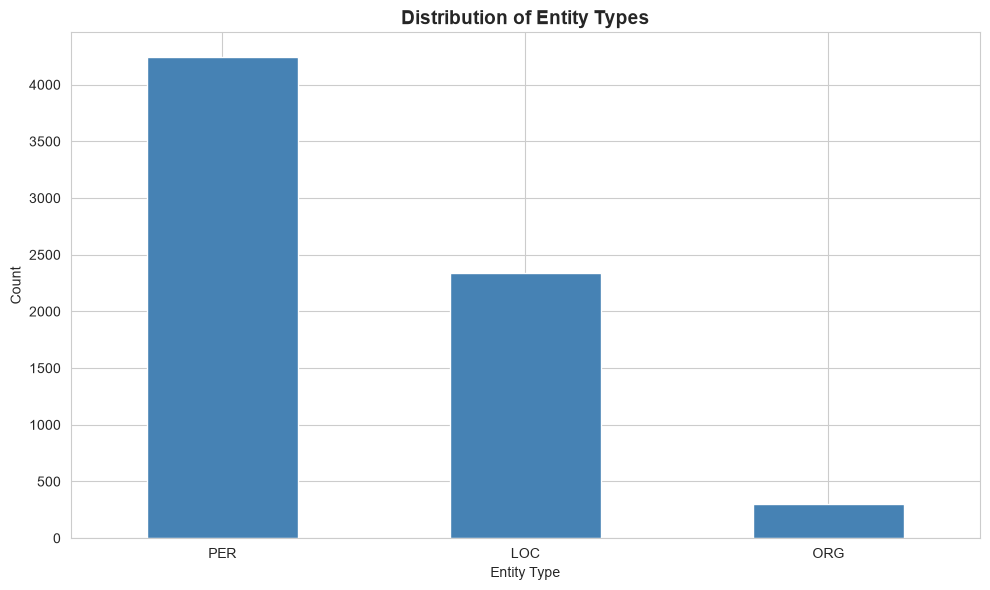

In [ ]:
# entity type distribution
entity_counts = entities_df['entity_group'].value_counts()

print('Entity types found:')
print(entity_counts)
print()

# visualize
plt.figure(figsize=(10, 6))
entity_counts.plot(kind='bar', color='steelblue')
plt.title('Distribution of Entity Types', fontsize=14, fontweight='bold')
plt.xlabel('Entity Type')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Top 20 most mentioned locations:
text
Samoa            86
Bournemouth      80
Edinburgh        68
Vailima          66
England          49
Scotland         39
Sydney           35
Honolulu         34
San Francisco    31
Davos            31
London           26
Skerryvore       26
New York         25
States           24
Monterey         23
Hyeres           22
Saranac Lake     21
Var              19
South Seas       19
Paris            18
Name: count, dtype: int64



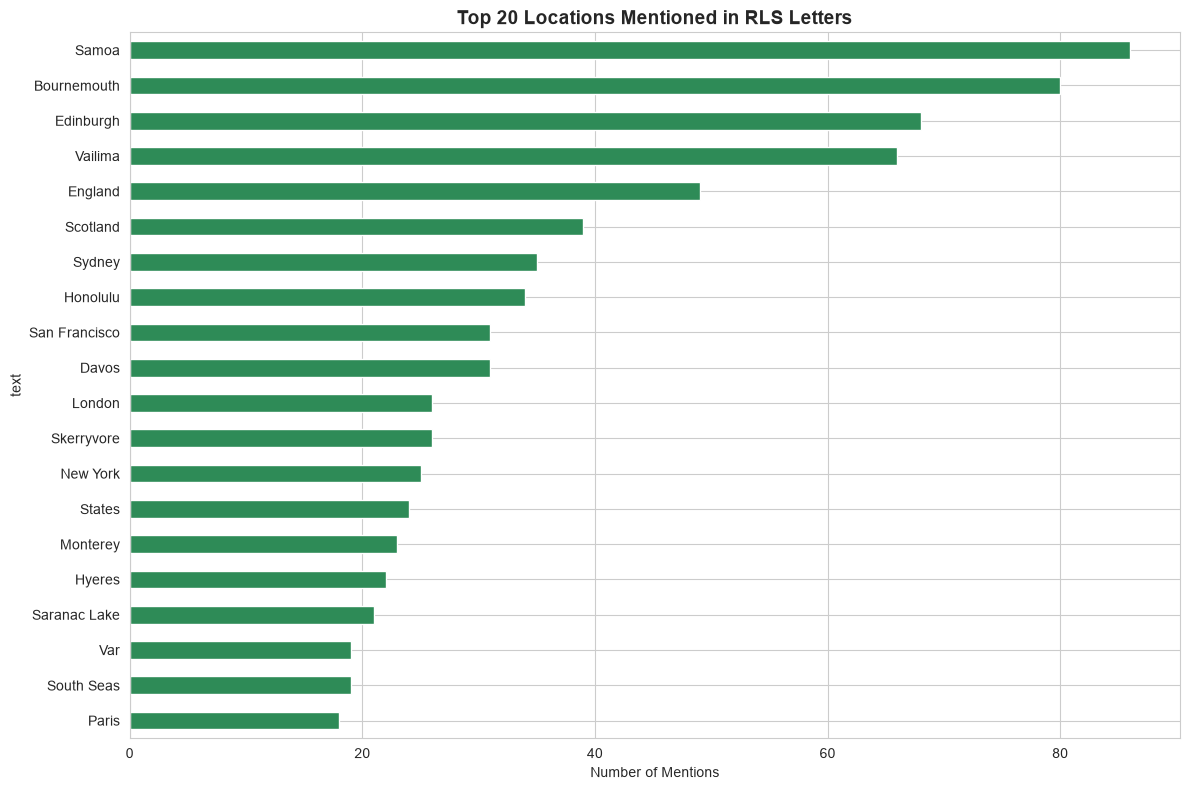

In [ ]:
# most frequently mentioned locations
locations = entities_df[entities_df['entity_group'] == 'LOC']['text'].value_counts().head(20)

print('Top 20 most mentioned locations:')
print(locations)
print()

# visualize
plt.figure(figsize=(12, 8))
locations.plot(kind='barh', color='seagreen')
plt.title('Top 20 Locations Mentioned in RLS Letters', fontsize=14, fontweight='bold')
plt.xlabel('Number of Mentions')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Top 20 most mentioned people:
text
Robert Louis Stevenson    205
R. L. S                   188
God                       138
Fanny                      63
Lloyd                      59
Sidney Colvin              50
Henley                     47
R. L. Stevenson            41
Colvin                     41
Charles                    41
Thomas Stevenson           39
Gosse                      39
Henry James                38
Stevenson                  37
Burns                      32
Charles Baxter             32
Edmund Gosse               29
W. E. Henley               28
James                      28
Scott                      26
Name: count, dtype: int64



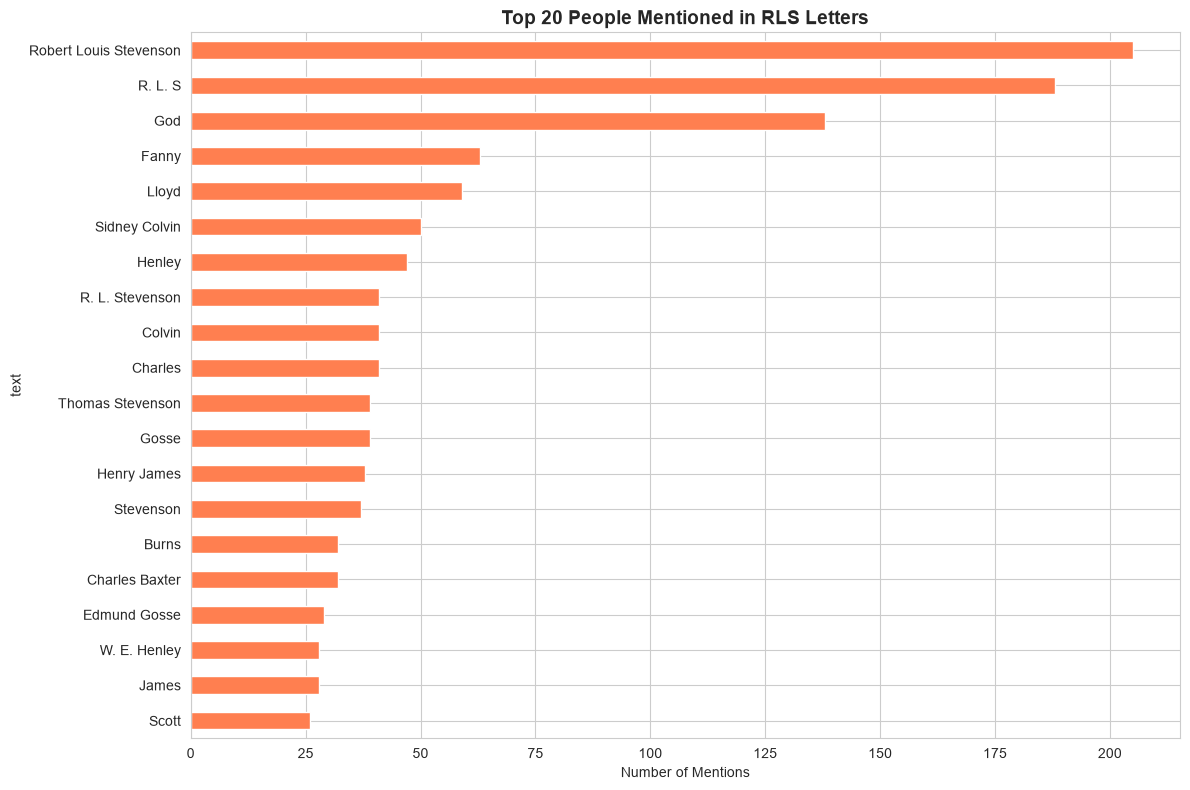

In [ ]:
# most frequently mentioned people
people = entities_df[entities_df['entity_group'] == 'PER']['text'].value_counts().head(20)

print('Top 20 most mentioned people:')
print(people)
print()

# visualize
plt.figure(figsize=(12, 8))
people.plot(kind='barh', color='coral')
plt.title('Top 20 People Mentioned in RLS Letters', fontsize=14, fontweight='bold')
plt.xlabel('Number of Mentions')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Section 5: Entity Resolution

NER models extract *surface forms*, i.e. the exact text as it appears in the original. This means the same real-world entity can appear under several different names:

| Surface form | Refers to |
|---|---|
| `Robert Louis Stevenson` | the author himself |
| `R. L. Stevenson` | the author himself |
| `R. L. S.` | the author himself |
| `Colvin` | Sidney Colvin, his friend and editor |

**Entity resolution** is the task of mapping these surface forms to a single canonical identifier. A related task, *entity linking*, goes a step further, and connects each name to an entry in a knowledge base, such as Wikidata. You met this problem in the Gemini Notebook activity in Unit 2, which could resolve `Colvin` and `Sidney Colvin` in conversation but not as structured data. Here we'll do it with a hand-crafted dictionary: a practical first step when you know the material well.

We add the resolved name as a new `canonical` column, and keep the original surface form in `text`. The evaluation in Section 9 compares the model with what annotators wrote down, so it needs the surface forms.

In [18]:
# a dictionary mapping known surface forms to a canonical name
# keys are lowercase for case-insensitive matching
#
# note what is *not* here: plain 'stevenson'
# in these letters it can mean RLS, but also his father (Thomas Stevenson) or his mother
# resolving that needs context, not a dictionary
ENTITY_ALIASES = {
    'r. l. s.': 'Robert Louis Stevenson',
    'r.l.s.': 'Robert Louis Stevenson',
    'r. l. s': 'Robert Louis Stevenson',
    'r. l. stevenson': 'Robert Louis Stevenson',
    'r.l. stevenson': 'Robert Louis Stevenson',
    'r. l stevenson': 'Robert Louis Stevenson',
    'louis stevenson': 'Robert Louis Stevenson',
    'colvin': 'Sidney Colvin',
    's. colvin': 'Sidney Colvin',
}


def resolve_entity(name):
    """Return the canonical name for a surface form, or the original if unknown."""
    return ENTITY_ALIASES.get(name.strip().lower(), name)


# show the effect on a few surface forms
examples = ['R. L. S.', 'Robert Louis Stevenson', 'R. L. Stevenson', 'Colvin', 'Stevenson']
print('Entity resolution examples:')
for name in examples:
    print(f'  {name!r:<30} -> {resolve_entity(name)!r}')

Entity resolution examples:
  'R. L. S.'                     -> 'Robert Louis Stevenson'
  'Robert Louis Stevenson'       -> 'Robert Louis Stevenson'
  'R. L. Stevenson'              -> 'Robert Louis Stevenson'
  'Colvin'                       -> 'Sidney Colvin'
  'Stevenson'                    -> 'Stevenson'


In [19]:
# check how often each surface form appears in the corpus
known_forms = [*ENTITY_ALIASES.keys(), 'robert louis stevenson', 'sidney colvin']
mask = entities_df['text'].str.lower().isin(known_forms)
print('Occurrences of known surface forms before resolution:')
print(entities_df[mask]['text'].value_counts().to_string())

Occurrences of known surface forms before resolution:
text
Robert Louis Stevenson    205
R. L. S                   189
Sidney Colvin              50
Colvin                     42
R. L. Stevenson            41
R. L. S.                   21
Louis Stevenson             2


In [20]:
# apply resolution to the full DataFrame, keeping the original surface form in `text`
entities_df['canonical'] = entities_df['text'].apply(resolve_entity)

resolved_count = (entities_df['canonical'] != entities_df['text']).sum()
print(f'Resolved {resolved_count} entity mentions across the corpus.')
print('\nTop 10 people after resolution:')
print(entities_df[entities_df['entity_group'] == 'PER']['canonical'].value_counts().head(10).to_string())

Resolved 295 entity mentions across the corpus.

Top 10 people after resolution:
canonical
Robert Louis Stevenson    456
God                       138
Sidney Colvin              91
Fanny                      63
Lloyd                      59
Henley                     47
Charles                    41
Thomas Stevenson           39
Gosse                      39
Henry James                38


## Section 6: Network Analysis

Next, we'll create a network graph showing relationships between people mentioned in the letters. Two people are connected if they are mentioned in the same letter. We use the resolved names, so that `Colvin` and `Sidney Colvin` count as one person.

In [21]:
# get people mentioned in each letter
people_df = entities_df[entities_df['entity_group'] == 'PER'].copy()

# group by letter
people_by_letter = people_df.groupby('file_name')['canonical'].apply(list).to_dict()

# create edges: two people are connected if they appear in the same letter
edges = []
for people in people_by_letter.values():
    # get unique people in this letter, sorted so the network is built the same way every time
    unique_people = sorted(set(people))
    # create edges for all pairs (a letter that mentions only one person has none)
    for person1, person2 in combinations(unique_people, 2):
        edges.append((person1, person2))

print(f'Created {len(edges)} co-occurrence edges')

Created 18350 co-occurrence edges


In [22]:
# build network graph
G = nx.Graph()
G.add_edges_from(edges)

print(f'Network has {G.number_of_nodes()} nodes and {G.number_of_edges()} edges')

# keep only the largest connected component for visualization
largest_cc = max(nx.connected_components(G), key=len)
G_main = G.subgraph(largest_cc).copy()

print(f'Largest connected component: {G_main.number_of_nodes()} nodes, {G_main.number_of_edges()} edges')

Network has 1610 nodes and 15955 edges
Largest connected component: 1605 nodes, 15951 edges


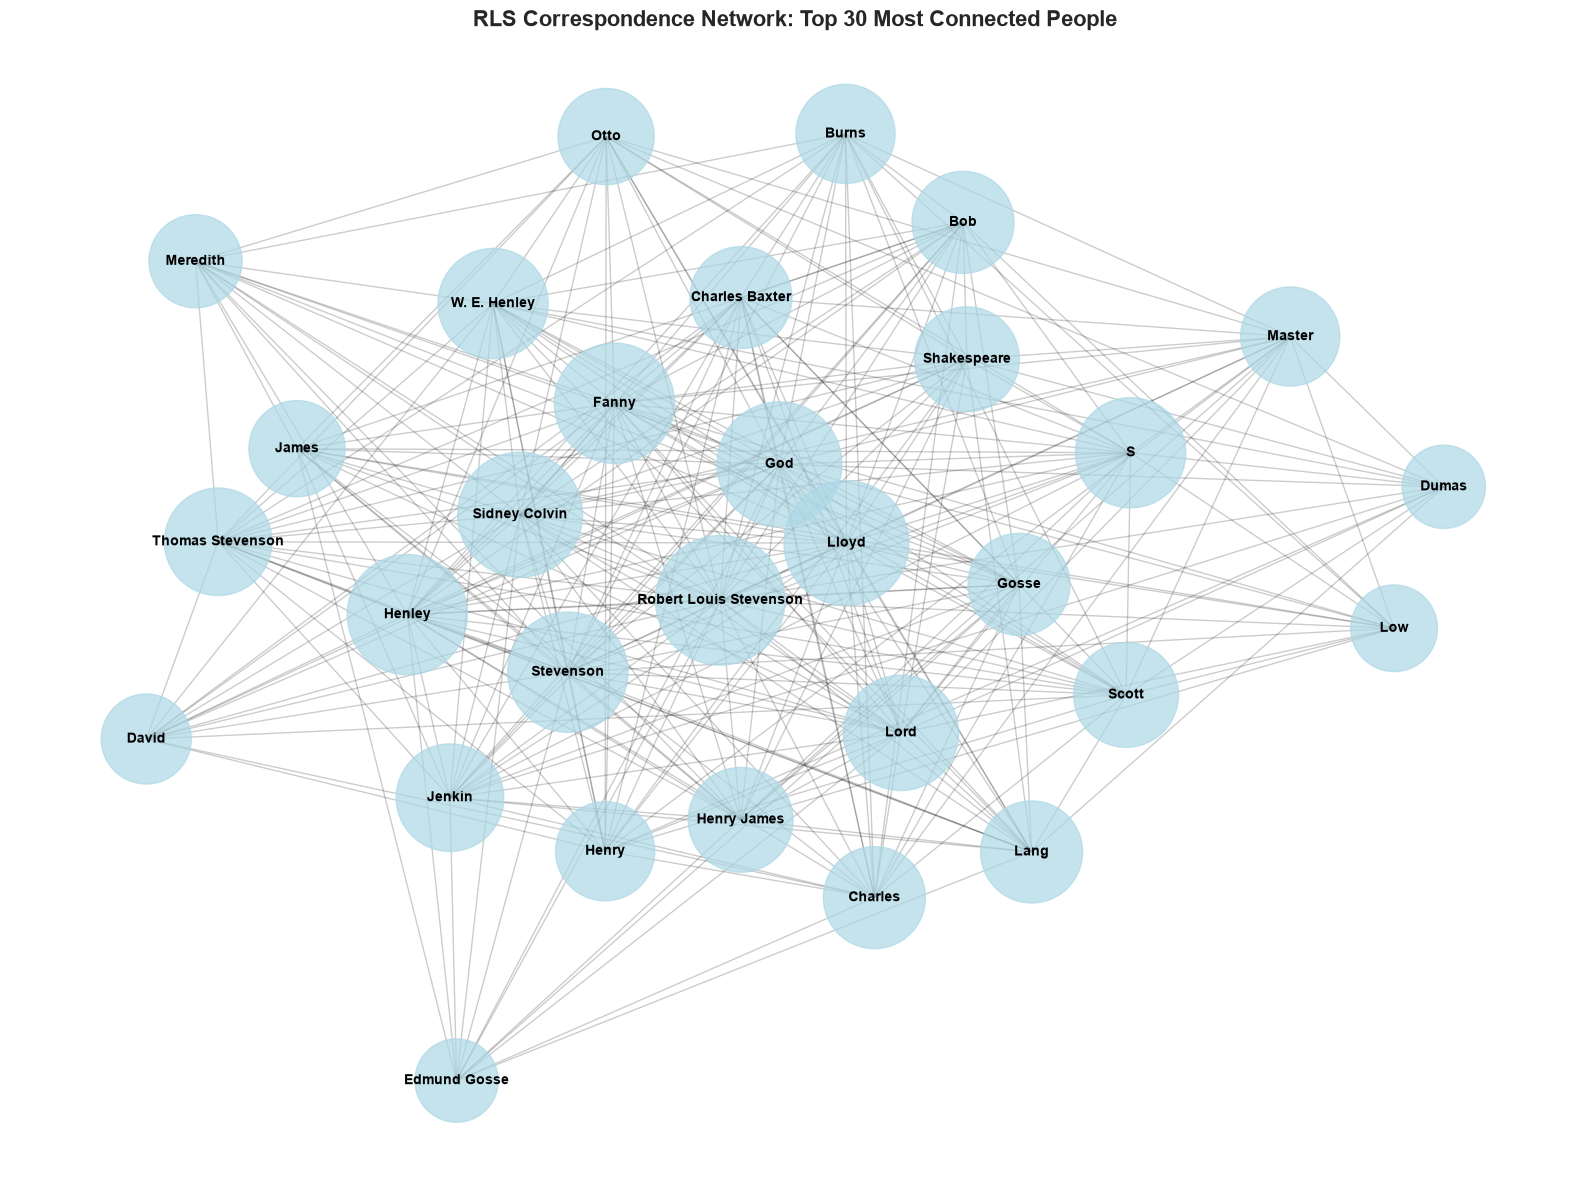

In [23]:
# filter to top 30 most connected people for clearer visualization
# (ties are broken alphabetically, and the subgraph is built in a fixed order, so the drawing is the same every time)
degree_dict = dict(G_main.degree())
top_nodes = sorted(degree_dict, key=lambda person: (-degree_dict[person], person))[:30]
G_viz = nx.Graph()
G_viz.add_nodes_from(top_nodes)
G_viz.add_edges_from(sorted(tuple(sorted(edge)) for edge in G_main.subgraph(top_nodes).edges()))

# visualize
plt.figure(figsize=(16, 12))

# use spring layout
pos = nx.spring_layout(G_viz, k=0.5, iterations=50, seed=42)

# node sizes based on degree
node_sizes = [300 * G_viz.degree(node) for node in G_viz.nodes()]

# draw
nx.draw_networkx_nodes(G_viz, pos, node_size=node_sizes, node_color='lightblue', alpha=0.7)
nx.draw_networkx_edges(G_viz, pos, alpha=0.2)
nx.draw_networkx_labels(G_viz, pos, font_size=10, font_weight='bold')

plt.title('RLS Correspondence Network: Top 30 Most Connected People', fontsize=16, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

In [24]:
# identify central figures
centrality = nx.degree_centrality(G_viz)
top_central = sorted(centrality.items(), key=lambda x: (-x[1], x[0]))[:10]  # ties in alphabetical order

print("Top 10 most central people in RLS's network:")
for person, score in top_central:
    print(f'  {person:<30} | Centrality: {score:.3f}')

Top 10 most central people in RLS's network:
  Robert Louis Stevenson         | Centrality: 1.000
  God                            | Centrality: 0.931
  Lloyd                          | Centrality: 0.931
  Sidney Colvin                  | Centrality: 0.931
  Fanny                          | Centrality: 0.862
  Henley                         | Centrality: 0.862
  Stevenson                      | Centrality: 0.862
  Lord                           | Centrality: 0.793
  S                              | Centrality: 0.724
  W. E. Henley                   | Centrality: 0.724


## Section 7: Timeline Analysis

Next, we'll track mentions of some of RLS's main correspondents over time.

We match on surnames, which is crude: `James` matches Henry James, but also anyone else called James. This is the entity resolution problem again. Letters with no known year are dropped.

In [25]:
# some of RLS's main correspondents
key_people = ['Colvin', 'Gosse', 'Henley', 'Baxter', 'James']

# filter entities
timeline_df = people_df[people_df['canonical'].str.contains('|'.join(key_people), case=False)].copy()

# convert year to numeric
timeline_df['year_num'] = pd.to_numeric(timeline_df['year'], errors='coerce')
timeline_df = timeline_df.dropna(subset=['year_num'])

# label each mention with the key person it matched
timeline_df['person'] = timeline_df['canonical'].str.extract('(' + '|'.join(key_people) + ')', flags=re.IGNORECASE)[0]

# count mentions per person per year
timeline_counts = timeline_df.groupby(['year_num', 'person']).size().reset_index(name='count')

timeline_counts.head()

,year_num,person,count
0,1872.0,Baxter,6
1,1873.0,Baxter,4
2,1874.0,Colvin,1
3,1875.0,Baxter,2
4,1875.0,Colvin,5


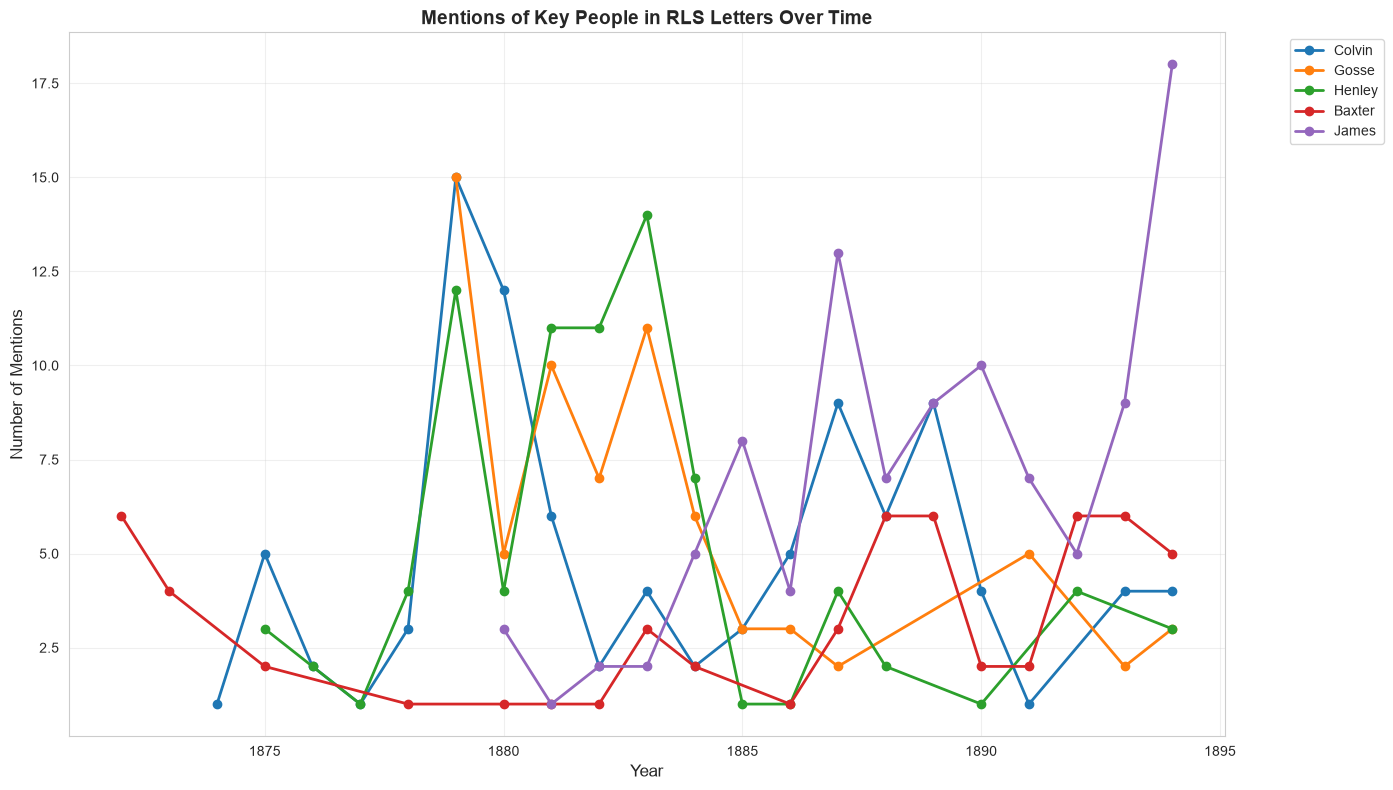

In [26]:
# plot timeline
plt.figure(figsize=(14, 8))

for person in key_people:
    person_data = timeline_counts[timeline_counts['person'].str.lower() == person.lower()]
    if len(person_data) > 0:
        plt.plot(person_data['year_num'], person_data['count'], marker='o', label=person, linewidth=2)

plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Mentions', fontsize=12)
plt.title('Mentions of Key People in RLS Letters Over Time', fontsize=14, fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Section 8: Mapping Places

Where was RLS, and where was he writing about? To put locations on a map, each place name has to be turned into coordinates, a step called **geocoding**. Like entity resolution, it's harder than it looks.

The coordinates come from `data/place_coordinates.csv`, which covers the 60 most-mentioned locations. They were looked up automatically with OpenStreetMap's Nominatim geocoder (see `code/build_place_coordinates.py`), then **every row was checked by hand**. The `review` column records the result: correct, approximate, wrong, not a place, or not found.

The map colours each place by that review, so you can see what an automatic pipeline would have produced if nobody had checked. Hover over a marker for its name, and click it for what the geocoder matched and why it's wrong.

In [27]:
import folium

places = pd.read_csv(DATA_DIR / 'place_coordinates.csv')
print('Review of the geocoded places:')
print(places['review'].value_counts().to_string())

REVIEW_COLORS = {'correct': 'green', 'approximate': 'orange', 'wrong': 'red', 'not a place': 'purple'}
print('\nMarker colors:', ', '.join(f'{review} = {color}' for review, color in REVIEW_COLORS.items()))

places_map = folium.Map(
    location=[30, 0],
    zoom_start=2,
    tiles='https://tile.openstreetmap.org/{z}/{x}/{y}.png',
    attr='&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> contributors',
)

for _, row in places.dropna(subset=['latitude']).iterrows():
    popup = f'<b>{row["place"]}</b> ({row["mentions"]} mentions)<br>Geocoded as: {row["geocoded_as"]}<br>Review: {row["review"]}'
    if isinstance(row['note'], str):
        popup += f'<br>{row["note"]}'
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=3 + row['mentions'] ** 0.5 * 1.5,  # bigger circles for more mentions
        color=REVIEW_COLORS.get(row['review'], 'gray'),
        fill=True,
        fill_opacity=0.6,
        tooltip=f'{row["place"]} ({row["mentions"]} mentions)',
        popup=folium.Popup(popup, max_width=300),
    ).add_to(places_map)

places_map

Review of the geocoded places:
review
correct        34
not a place     9
approximate     8
wrong           7
not found       2

Marker colors: correct = green, approximate = orange, wrong = red, not a place = purple


If you're reading this notebook on GitHub, the interactive map won't display, but the next cell lists the rows the review flagged.

In [28]:
problems = places[~places['review'].isin(['correct'])]
problems[['place', 'mentions', 'geocoded_as', 'review', 'note']]

,place,mentions,geocoded_as,review,note
11,Skerryvore,26,"Skerryvore, Argyll and Bute, Alba / Scotland, ...",wrong,RLS's house in Bournemouth (1885–87)
12,New York,25,"New York, United States",approximate,city or state? geocoded to state
13,States,24,United States,approximate,plotted at the centre of the USA
14,Monterey,23,"Monterey County, California, United States",approximate,geocoded to county not town
18,South Seas,19,"South Seas, Collins Avenue, Miami Beach, Miami...",not a place,NaN
23,Treasure Island,16,"Treasure Island, San Francisco, California, Un...",not a place,geocoded to an island in San Francisco Bay
25,Hyeres - Les - Palmiers,15,"Les Palmiers, Rue du Ceinturon, L'Ayguade, Hyè...",approximate,NaN
26,Europe,14,Europe,approximate,continent
27,S,14,"Département du Sud, Ayiti",not a place,NaN
28,Upolu,14,"Upolu Airport, Upolu Airport Road, Hikapoloa, ...",wrong,"the island in Samoa where Vailima is, geocoded..."


Look at the wrong rows. `Skerryvore` was RLS's house in Bournemouth, named after a lighthouse, so the geocoder put it at the lighthouse off the Scottish island of Tiree. `Upolu`, the island in Samoa where he lived, landed at an airport in Hawaii. The geocoder had only a bare name and no context, so it guessed. And some *places* aren't places at all: they are NER errors (`Treasure Island` is a novel, and `Heaven` landed at a London nightclub) that a map quietly turns into dots.

Every step in a pipeline like this (extraction, resolution, geocoding) adds its own errors, and they compound. A map is persuasive, which is exactly why each step needs checking.

## Section 9: Evaluation with Human Annotations

How well does the model actually perform? To find out, we need **ground truth**: letters annotated by people, to compare the model's output against. See [the example](https://gpizzorno.github.io/understanding-ai/unit_1/evaluation_metrics.html) for how precision, recall, and F1 are calculated.

### The Annotations

The repository includes two sets of annotations of the same eight letters from `data/sample_letters/`, made independently by two people:

- `data/annotations/person_1_annotations.csv`
- `data/annotations/person_2_annotations.csv`

Each has one row per entity mentioned in a letter: the letter's `file_name`, the `entity_text` exactly as written, and its `entity_type` (`PER`, `LOC`, or `ORG`).

Having two annotators lets us ask two questions: how well does the model agree with a person, and how well do two people agree with *each other*? The second question tells us how much to trust the first.

By default, the model is evaluated against `person_1`. Change `REFERENCE` in the cell below to evaluate it against someone else.

### Adding Your Own Annotations

1. Copy `data/annotations/annotation_template.csv` to `data/annotations/my_annotations.csv`.
2. Annotate some of the eight letters listed below, following the [annotation activity](https://gpizzorno.github.io/understanding-ai/unit_3/annotation.html). Don't look at the other annotators' files first.
3. Re-run this section. Every CSV file in `data/annotations/` is loaded as a separate annotator, named after the file (`my_annotations.csv` becomes `my`), so your annotations are compared with both people and with the model. Set `REFERENCE = 'my'` to evaluate the model against your own ground truth.

**In a workshop:** annotations can be collected in a shared Google Sheet instead. Publish it as CSV (`File → Share → Publish to web → CSV`) and paste the URL into `SHEET_CSV_URL`. It's loaded as an annotator called `workshop_sheet`.

In [29]:
# the annotator whose annotations we treat as ground truth for evaluating the model
REFERENCE = 'person_1'

# in a workshop: paste the URL of a Google Sheet published as CSV
SHEET_CSV_URL = None

In [30]:
ANNOTATIONS_DIR = DATA_DIR / 'annotations'


def load_annotations(source):
    """Load one annotator's CSV file (or URL), normalizing it to match the model's input."""
    df = pd.read_csv(source)
    df.columns = df.columns.str.strip()
    df = df[['file_name', 'entity_text', 'entity_type']].dropna()
    df['entity_text'] = df['entity_text'].astype(str).str.strip().apply(normalize_caps)
    df['entity_type'] = df['entity_type'].str.strip().str.upper()
    return df.drop_duplicates()


# every CSV in data/annotations/ (except the template) is one annotator, named after the file
annotators = {}
for path in sorted(ANNOTATIONS_DIR.glob('*.csv')):
    if path.name == 'annotation_template.csv':
        continue
    df = load_annotations(path)
    if len(df) > 0:
        annotators[path.stem.removesuffix('_annotations')] = df
if SHEET_CSV_URL:
    annotators['workshop_sheet'] = load_annotations(SHEET_CSV_URL)

summary = pd.DataFrame(
    {
        name: {
            'letters': df['file_name'].nunique(),
            'annotations': len(df),
            **df['entity_type'].value_counts().reindex(['PER', 'LOC', 'ORG'], fill_value=0).to_dict(),
        }
        for name, df in annotators.items()
    }
).T
print('Annotators:\n')
print(summary.to_string())

Annotators:

          letters  annotations  PER  LOC  ORG
person_1        8          107   67   29   11
person_2        8           88   50   26   12


In [31]:
# which letters has each annotator annotated?
annotated_letters = sorted(set().union(*(df['file_name'] for df in annotators.values())))
coverage = pd.DataFrame(
    {name: ['x' if f in set(df['file_name']) else '' for f in annotated_letters] for name, df in annotators.items()},
    index=annotated_letters,
)
print(coverage.to_string())

annotations_df = annotators[REFERENCE]
print(
    f'\nReference annotator: {REFERENCE} ({len(annotations_df)} annotations in {annotations_df["file_name"].nunique()} letters)'
)

                                  person_1 person_2
wikisource_vol1_ch1_letter3.txt          x        x
wikisource_vol1_ch3_letter14.txt         x        x
wikisource_vol1_ch3_letter31.txt         x        x
wikisource_vol1_ch4_letter18.txt         x        x
wikisource_vol1_ch6_letter27.txt         x        x
wikisource_vol2_ch10_letter2.txt         x        x
wikisource_vol2_ch11_letter18.txt        x        x
wikisource_vol2_ch12_letter17.txt        x        x

Reference annotator: person_1 (107 annotations in 8 letters)


Now compare the model's predictions with the reference annotations. For each annotated letter and entity type, we compare the *set* of entity names the annotator recorded with the set the model predicted:

- **true positive (TP):** in both
- **false positive (FP):** predicted by the model, but not annotated
- **false negative (FN):** annotated, but missed by the model

We then add up the counts across letters and compute precision, recall, and F1 for each entity type.

In [32]:
ENTITY_TYPES = ['PER', 'LOC', 'ORG']


def compute_metrics(tp, fp, fn):
    """Return precision, recall, and F1 from true positive, false positive, and false negative counts."""
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return {'precision': precision, 'recall': recall, 'f1': f1}


def evaluate(predictions, annotations):
    """Compare model predictions with human annotations, per entity type (micro-averaged across letters)."""
    rows = []
    for etype in ENTITY_TYPES:
        totals = {'tp': 0, 'fp': 0, 'fn': 0}

        for fname in annotations['file_name'].unique():
            # ground truth: what the annotators labelled (case-insensitive)
            gt = annotations[(annotations['file_name'] == fname) & (annotations['entity_type'] == etype)]
            gt_set = set(gt['entity_text'].str.strip().str.lower())

            # model predictions for the same letter and type
            pred = predictions[(predictions['file_name'] == fname) & (predictions['entity_group'] == etype)]
            pred_set = set(pred['text'].str.strip().str.lower())

            totals['tp'] += len(gt_set & pred_set)
            totals['fp'] += len(pred_set - gt_set)
            totals['fn'] += len(gt_set - pred_set)

        rows.append({'entity_type': etype, **compute_metrics(**totals), **totals})

    return pd.DataFrame(rows).set_index('entity_type')


metrics_df = evaluate(entities_df, annotations_df)

print('Evaluation results (micro-averaged across annotated letters)\n')
print(metrics_df[['precision', 'recall', 'f1', 'tp', 'fp', 'fn']].round(3).to_string())

Evaluation results (micro-averaged across annotated letters)

             precision  recall     f1  tp  fp  fn
entity_type                                      
PER              0.566   0.712  0.631  47  36  19
LOC              0.781   0.862  0.820  25   7   4
ORG              0.500   0.455  0.476   5   5   6


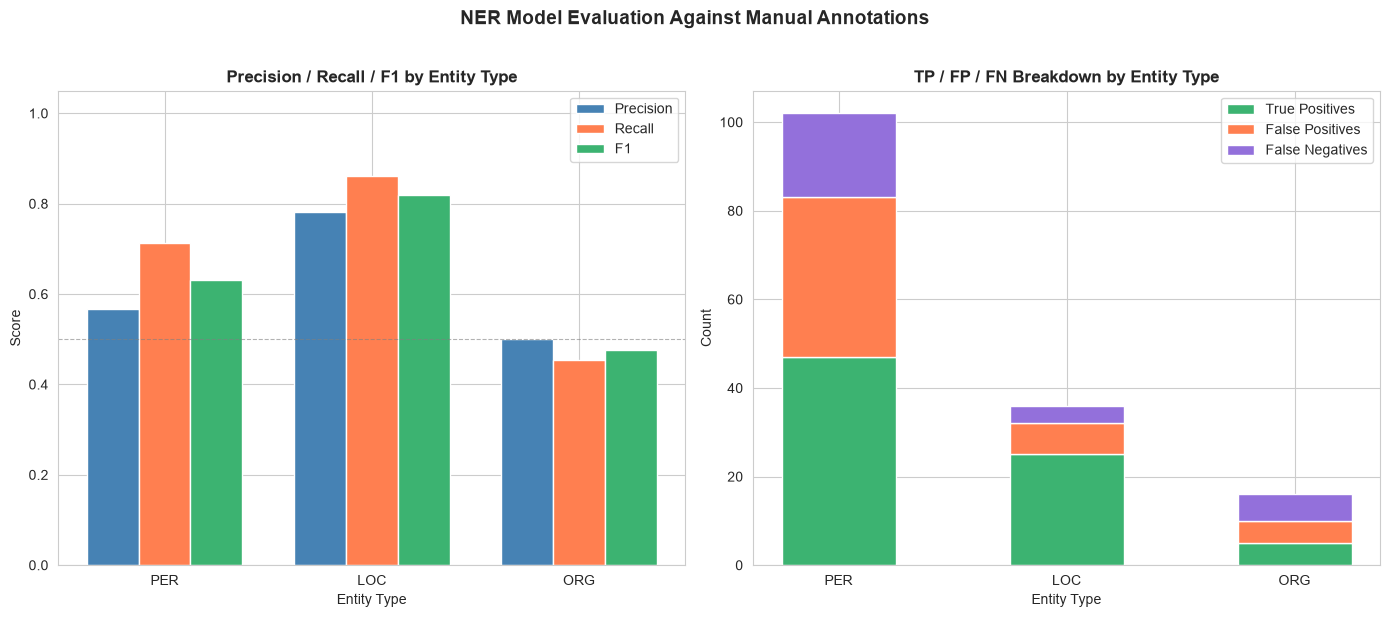

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# left: grouped bar chart of P / R / F1 per entity type
x = range(len(metrics_df))
width = 0.25
colors = {'precision': 'steelblue', 'recall': 'coral', 'f1': 'mediumseagreen'}

for i, (metric, color) in enumerate(colors.items()):
    axes[0].bar(
        [xi + i * width for xi in x],
        metrics_df[metric],
        width=width,
        label=metric.capitalize(),
        color=color,
    )

axes[0].set_xticks([xi + width for xi in x])
axes[0].set_xticklabels(metrics_df.index)
axes[0].set_ylim(0, 1.05)
axes[0].set_xlabel('Entity Type')
axes[0].set_ylabel('Score')
axes[0].set_title('Precision / Recall / F1 by Entity Type', fontweight='bold')
axes[0].legend()
axes[0].axhline(0.5, color='grey', linestyle='--', linewidth=0.8, alpha=0.6)

# right: stacked bar of TP / FP / FN per entity type
bar_width = 0.5
axes[1].bar(metrics_df.index, metrics_df['tp'], bar_width, label='True Positives', color='mediumseagreen')
axes[1].bar(
    metrics_df.index, metrics_df['fp'], bar_width, label='False Positives', color='coral', bottom=metrics_df['tp']
)
axes[1].bar(
    metrics_df.index,
    metrics_df['fn'],
    bar_width,
    label='False Negatives',
    color='mediumpurple',
    bottom=metrics_df['tp'] + metrics_df['fp'],
)

axes[1].set_xlabel('Entity Type')
axes[1].set_ylabel('Count')
axes[1].set_title('TP / FP / FN Breakdown by Entity Type', fontweight='bold')
axes[1].legend()

plt.suptitle('NER Model Evaluation Against Manual Annotations', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### The Choice of Ground Truth

The scores above treat one person's annotations as the truth. What happens if we use the other person's instead? The next cell evaluates the model against every annotator, on the letters each of them annotated.

In [34]:
by_annotator = {}
for name, df in annotators.items():
    m = evaluate(entities_df, df)
    overall = compute_metrics(**m[['tp', 'fp', 'fn']].sum())
    by_annotator[name] = {**{f'F1 {etype}': m.loc[etype, 'f1'] for etype in ENTITY_TYPES}, 'F1 overall': overall['f1']}

print(f'Model ({MODEL_NAME}) evaluated against each annotator\n')
print(pd.DataFrame(by_annotator).T.round(3).to_string())

Model (Davlan/bert-base-multilingual-cased-ner-hrl) evaluated against each annotator



          F1 PER  F1 LOC  F1 ORG  F1 overall
person_1   0.631    0.82   0.476       0.667
person_2   0.541    0.69   0.364       0.563


### Error Analysis

The numbers tell you *how much* the model gets wrong, but not *what* it gets wrong. The next cell lists the disagreements between the model and the reference annotator for each letter. Look for patterns: are the errors random, or systematic? Name variants, honorifics, titles of works, places that are also surnames? And are they all really the model's errors, or are some of them debatable annotation decisions?

In [35]:
for fname in annotations_df['file_name'].unique():
    print(f'=== {fname}')
    for etype in ENTITY_TYPES:
        gt = annotations_df[(annotations_df['file_name'] == fname) & (annotations_df['entity_type'] == etype)]
        pred = entities_df[(entities_df['file_name'] == fname) & (entities_df['entity_group'] == etype)]
        gt_set = set(gt['entity_text'].str.strip().str.lower())
        pred_set = set(pred['text'].str.strip().str.lower())
        if gt_set - pred_set:
            print(f'  {etype} missed by the model (FN):     {sorted(gt_set - pred_set)}')
        if pred_set - gt_set:
            print(f'  {etype} not in the annotations (FP):  {sorted(pred_set - gt_set)}')
    print()

=== wikisource_vol1_ch3_letter14.txt
  PER missed by the model (FN):     ['colvin']
  PER not in the annotations (FP):  ['clever']

=== wikisource_vol1_ch1_letter3.txt
  PER missed by the model (FN):     ['thomas stevenson']
  PER not in the annotations (FP):  ['thomas stevenson wick']
  LOC missed by the model (FN):     ['stornoway']
  LOC not in the annotations (FP):  ['##ck', 'highland']

=== wikisource_vol1_ch3_letter31.txt
  PER missed by the model (FN):     ['r. l. s.', 's.']
  PER not in the annotations (FP):  ['god', 'miss s.', 'r. l. s', 'sawbat']
  ORG missed by the model (FN):     ['spectator']

=== wikisource_vol1_ch4_letter18.txt
  PER missed by the model (FN):     ['greisengesang', 'r. l. s.', 'stephen', 'z.']
  PER not in the annotations (FP):  ['benjamin franklin', 'cancellarius greisengesang', 'countess von rosen', 'duchess', 'hester', 'hester noble', 'macmillan', 'madame z', 'prince', 'r. l. s', 'semiramis', 'stephen. yoshida torajiro', 'thoreau', 'william penn']
  OR

### Inter-Annotator Agreement

How reliable is the ground truth itself? Real annotation projects measure how often independent annotators agree before trusting their annotations.

A standard measure is **Cohen's *kappa***. We label every word in a letter as PER, LOC, ORG, or O (not part of an entity), once for each annotator, and compare the two label sequences. *Kappa* corrects for agreement you'd expect by chance: 1 means perfect agreement, 0 means no better than chance. Because most words are O, raw percentage agreement always looks high, so *kappa* is more informative.

The next cell compares every pair of annotators on the letters they both annotated, and also treats the model as one more *annotator*. Compare the numbers: if two people agree with each other only somewhat better than the model agrees with either of them, what does that tell you about the model's scores?

In [36]:
from sklearn.metrics import cohen_kappa_score


def word_labels(text, entities):
    """Label each word in a text PER/LOC/ORG/O, given a list of (entity_text, entity_type) pairs."""
    text = normalize_caps(text)
    words = list(re.finditer(r'\w+', text))
    labels = ['O'] * len(words)
    for entity_text, entity_type in entities:
        pattern = r'(?<!\w)' + re.escape(entity_text) + r'(?!\w)'
        for match in re.finditer(pattern, text, flags=re.IGNORECASE):
            for i, word in enumerate(words):
                if word.start() < match.end() and word.end() > match.start():
                    labels[i] = entity_type
    return labels


# everyone to compare: the human annotators, plus the model in the same format
model_as_annotator = entities_df[entities_df['entity_group'].isin(ENTITY_TYPES)].rename(
    columns={'text': 'entity_text', 'entity_group': 'entity_type'}
)
sources = {**annotators, 'model': model_as_annotator}

rows = []
for name_a, name_b in combinations(sources, 2):
    df_a, df_b = sources[name_a], sources[name_b]
    shared = sorted(set(df_a['file_name']) & set(df_b['file_name']))
    if name_b == 'model':
        shared = sorted(df_a['file_name'].unique())  # the model covers every letter
    if not shared:
        continue
    labels_a, labels_b = [], []
    for fname in shared:
        text = (letters_dir / fname).read_text(encoding='utf-8')
        labels_a += word_labels(
            text, df_a[df_a['file_name'] == fname][['entity_text', 'entity_type']].itertuples(index=False)
        )
        labels_b += word_labels(
            text, df_b[df_b['file_name'] == fname][['entity_text', 'entity_type']].itertuples(index=False)
        )
    rows.append(
        {
            'pair': f'{name_a} vs {name_b}',
            'letters': len(shared),
            'words': len(labels_a),
            'raw agreement': sum(a == b for a, b in zip(labels_a, labels_b)) / len(labels_a),
            "Cohen's kappa": cohen_kappa_score(labels_a, labels_b),
        }
    )

agreement_df = pd.DataFrame(rows).set_index('pair')
print(agreement_df.round(3).to_string())

                      letters  words  raw agreement  Cohen's kappa
pair                                                              
person_1 vs person_2        8   4035          0.991          0.893
person_1 vs model           8   4035          0.982          0.814
person_2 vs model           8   4035          0.974          0.707


Where do the two people disagree? The next cell lists, for each letter, the entities only one of them recorded, and the ones they both recorded but gave different types. Most disagreements fall into three kinds: **boundaries** (was `Mr.` part of the name?), **types** (is a magazine an organization or a place?), and **coverage** (one person marked something the other didn't). Which kinds do you see?

In [37]:
ANNOTATOR_A, ANNOTATOR_B = 'person_1', 'person_2'
df_a, df_b = annotators[ANNOTATOR_A], annotators[ANNOTATOR_B]

for fname in sorted(set(df_a['file_name']) & set(df_b['file_name'])):
    a = {
        (t.lower(), ty)
        for t, ty in df_a[df_a['file_name'] == fname][['entity_text', 'entity_type']].itertuples(index=False)
    }
    b = {
        (t.lower(), ty)
        for t, ty in df_b[df_b['file_name'] == fname][['entity_text', 'entity_type']].itertuples(index=False)
    }
    type_conflicts = {t for t, _ in a - b} & {t for t, _ in b - a}
    only_a = sorted(f'{t} ({ty})' for t, ty in a - b if t not in type_conflicts)
    only_b = sorted(f'{t} ({ty})' for t, ty in b - a if t not in type_conflicts)
    if not (only_a or only_b or type_conflicts):
        continue
    print(f'=== {fname}')
    if only_a:
        print(f'  only {ANNOTATOR_A}: {only_a}')
    if only_b:
        print(f'  only {ANNOTATOR_B}: {only_b}')
    for t in sorted(type_conflicts):
        types_a = sorted(ty for tt, ty in a if tt == t)
        types_b = sorted(ty for tt, ty in b if tt == t)
        print(f'  different types for {t!r}: {ANNOTATOR_A} {types_a}, {ANNOTATOR_B} {types_b}')
    print()

=== wikisource_vol1_ch1_letter3.txt
  only person_1: ['free church (ORG)']
  only person_2: ['the free church (ORG)']

=== wikisource_vol1_ch3_letter14.txt
  only person_2: ['post-office (ORG)']

=== wikisource_vol1_ch3_letter31.txt
  only person_1: ['heriot row (LOC)', 's. (PER)', 'spectator (ORG)']
  only person_2: ['17 heriot row (LOC)', 'the spectator (ORG)']

=== wikisource_vol1_ch4_letter18.txt
  only person_1: ['amelia seraphina (PER)', 'bush street (LOC)', 'conrad (PER)', 'gondremarck (PER)', 'greisengesang (PER)', 'grunwald (LOC)', 'killian gottesacker (PER)', 'ottilie (PER)', 'otto frederick john (PER)', 'river farm (LOC)', 'seraphina (PER)', 'von rosen (PER)', 'z. (PER)']
  only person_2: ['608 bush street (LOC)']

=== wikisource_vol2_ch10_letter2.txt
  only person_1: ['dangerous archipelago (LOC)']

=== wikisource_vol2_ch11_letter18.txt
  only person_1: ['q. (PER)']

=== wikisource_vol2_ch12_letter17.txt
  only person_1: ['clifton (PER)', 'fountainhall (PER)', 'g. (PER)', '

### Confidence Thresholds

Each prediction comes with a confidence `score`. If we only keep predictions above a threshold, we should get fewer false alarms (higher precision), at the cost of missing more entities (lower recall). The next cell tries a range of thresholds against the reference annotations, so you can see this tradeoff on real data.

           precision  recall     f1
threshold                          
0.00           0.616   0.726  0.667
0.50           0.621   0.726  0.670
0.60           0.631   0.726  0.675
0.70           0.650   0.717  0.682
0.80           0.658   0.708  0.682
0.90           0.679   0.679  0.679
0.95           0.684   0.632  0.657
0.99           0.716   0.547  0.620

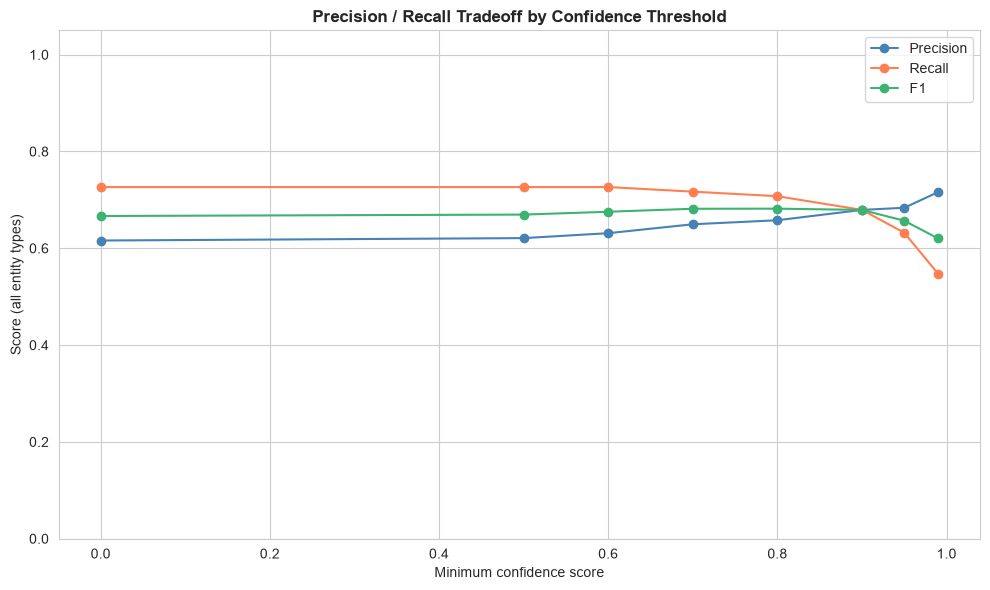

In [38]:
thresholds = [0.0, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]
sweep = []

for t in thresholds:
    m = evaluate(entities_df[entities_df['score'] >= t], annotations_df)
    totals = m[['tp', 'fp', 'fn']].sum()
    sweep.append({'threshold': t, **compute_metrics(**totals)})

sweep_df = pd.DataFrame(sweep).set_index('threshold')
print(sweep_df.round(3).to_string())

plt.figure(figsize=(10, 6))
for metric, color in [('precision', 'steelblue'), ('recall', 'coral'), ('f1', 'mediumseagreen')]:
    plt.plot(sweep_df.index, sweep_df[metric], marker='o', label=metric.capitalize(), color=color)
plt.xlabel('Minimum confidence score')
plt.ylabel('Score (all entity types)')
plt.ylim(0, 1.05)
plt.title('Precision / Recall Tradeoff by Confidence Threshold', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

## Section 10: Comparison with Another Model

Is a different model better at this task? Let's run [`dslim/bert-base-NER`](https://huggingface.co/dslim/bert-base-NER), an English-only model trained on news text, on the annotated letters, and evaluate it the same way.

This model also predicts a `MISC` type (miscellaneous entities), which isn't part of our annotation scheme, so the evaluation ignores it.

In [39]:
ALT_MODEL_NAME = 'dslim/bert-base-NER'

print('Loading alternative NER model... (this may take a minute the first time)')
alt_pipeline = pipeline(
    'ner',
    model=ALT_MODEL_NAME,
    aggregation_strategy='simple',  # combines subword tokens
    stride=128,  # read long letters in overlapping windows, instead of only their first 512 tokens
)

# run the alternative model on the annotated letters only
annotated_files = annotations_df['file_name'].unique()
alt_entities = []
for fname in annotated_files:
    alt_entities.extend(extract_entities_from_file(letters_dir / fname, ner=alt_pipeline))
alt_entities_df = pd.DataFrame(alt_entities)

print(f'{ALT_MODEL_NAME} found {len(alt_entities_df)} entities in {len(annotated_files)} annotated letters.')

Loading alternative NER model... (this may take a minute the first time)


dslim/bert-base-NER found 244 entities in 8 annotated letters.


Model comparison on the annotated letters

            Davlan/bert-base-multilingual-cased-ner-hrl               dslim/bert-base-NER              
                                              precision recall     f1           precision recall     f1
entity_type                                                                                            
PER                                               0.566  0.712  0.631               0.260  0.409  0.318
LOC                                               0.781  0.862  0.820               0.512  0.724  0.600
ORG                                               0.500  0.455  0.476               0.194  0.545  0.286


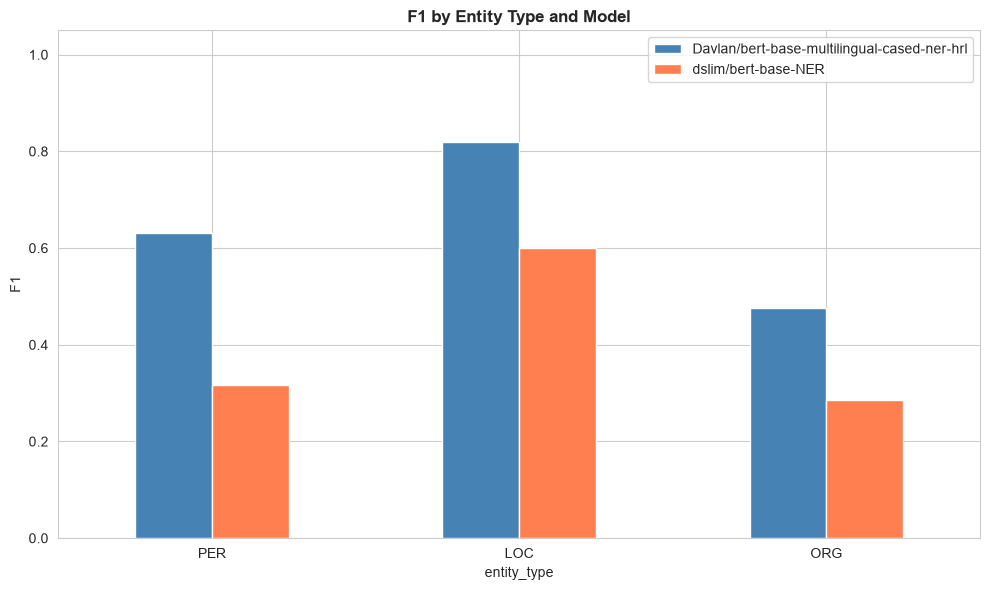

In [40]:
alt_metrics_df = evaluate(alt_entities_df, annotations_df)

comparison = pd.concat(
    {
        MODEL_NAME: metrics_df[['precision', 'recall', 'f1']],
        ALT_MODEL_NAME: alt_metrics_df[['precision', 'recall', 'f1']],
    },
    axis=1,
)
print('Model comparison on the annotated letters\n')
print(comparison.round(3).to_string())

comparison.xs('f1', axis=1, level=1).plot(kind='bar', figsize=(10, 6), color=['steelblue', 'coral'])
plt.title('F1 by Entity Type and Model', fontweight='bold')
plt.ylabel('F1')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### A Conversational AI Tool

In the [Gemini Notebook activity](https://gpizzorno.github.io/understanding-ai/unit_2/gemini_notebook.html) in Unit 2, you asked a conversational AI tool to find the people, places, and organizations in the 20 sample letters. The repository includes two CSV files that Gemini Notebook produced for exactly this task, from the same prompt, on the same day (see [`data/gemini_notebook/`](https://github.com/gpizzorno/understanding-ai/blob/main/data/gemini_notebook/README.md) for how they were made).

Before running the next cell, **make a prediction**: will a general-purpose AI tool do better or worse than the two NER models on these letters? The next cell evaluates both Gemini files against the same annotations, in the same way, and adds them to the comparison.

Gemini Notebook, run 1: 327 entities in 20 letters
Gemini Notebook, run 2: 325 entities in 20 letters

All four compared on the annotated letters (reference: person_1)

             Davlan/bert-base-multilingual-cased-ner-hrl  dslim/bert-base-NER  Gemini Notebook, run 1  Gemini Notebook, run 2
entity_type                                                                                                                  
PER                                                0.631                0.318                   0.756                   0.740
LOC                                                0.820                0.600                   0.820                   0.781
ORG                                                0.476                0.286                   0.720                   0.720


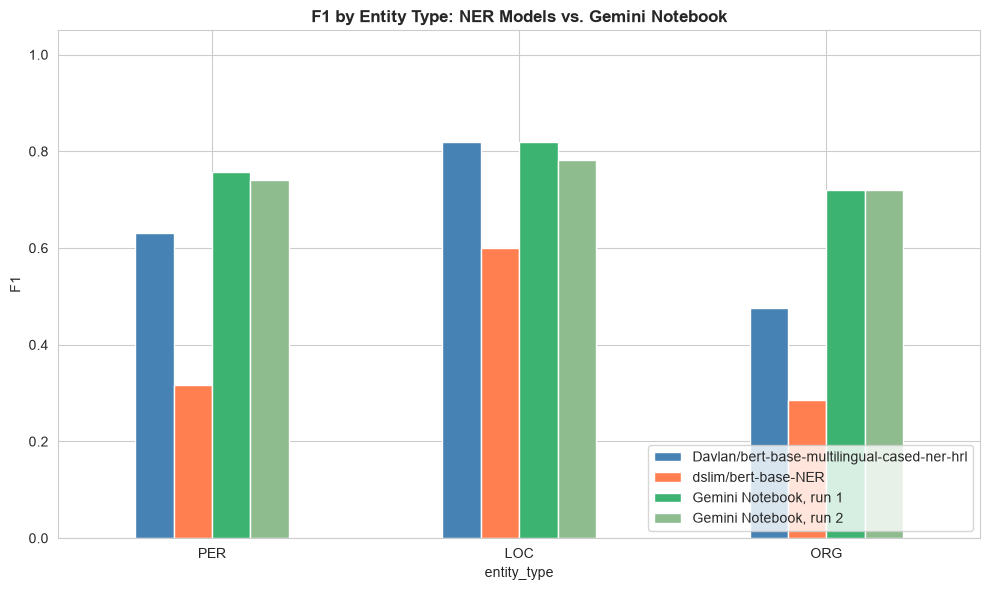

In [41]:
GEMINI_DIR = DATA_DIR / 'gemini_notebook'


def load_gemini(path):
    """Load a Gemini Notebook export into the same format as the NER model's predictions."""
    df = pd.read_csv(path).rename(columns={'entity_text': 'text', 'entity_type': 'entity_group'})
    df['text'] = df['text'].astype(str).str.strip().apply(normalize_caps)  # same preprocessing as the model
    df['entity_group'] = df['entity_group'].str.strip().str.upper()
    return df


gemini_runs = {
    'Gemini Notebook, run 1': load_gemini(GEMINI_DIR / 'extraction_run1.csv'),
    'Gemini Notebook, run 2': load_gemini(GEMINI_DIR / 'extraction_run2.csv'),
}
for name, df in gemini_runs.items():
    print(f'{name}: {len(df)} entities in {df["file_name"].nunique()} letters')

comparison_all = pd.concat(
    {
        MODEL_NAME: metrics_df[['precision', 'recall', 'f1']],
        ALT_MODEL_NAME: alt_metrics_df[['precision', 'recall', 'f1']],
        **{name: evaluate(df, annotations_df)[['precision', 'recall', 'f1']] for name, df in gemini_runs.items()},
    },
    axis=1,
)
print(f'\nAll four compared on the annotated letters (reference: {REFERENCE})\n')
print(comparison_all.xs('f1', axis=1, level=1).round(3).to_string())

comparison_all.xs('f1', axis=1, level=1).plot(
    kind='bar', figsize=(10, 6), color=['steelblue', 'coral', 'mediumseagreen', 'darkseagreen']
)
plt.title('F1 by Entity Type: NER Models vs. Gemini Notebook', fontweight='bold')
plt.ylabel('F1')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Gemini Notebook does considerably better than both NER models on people and organizations (on places, the main NER model is as good), mainly because it finds far more of the entities (higher recall). It catches `COLVIN` in `MY DEAR COLVIN`, initials such as `R. L. S.` and `Q.` (the writer Arthur Quiller-Couch), and names that are also ordinary words, such as `Low` and `Strong`, all of which the NER model missed. Compare the error-analysis cell above: many of the NER model's misses are exactly what a large language model, which reads each name in context, handles well. So why not just use it?

### Same Prompt, Same Sources, Different Data

Run the NER model on the same letter twice and you get exactly the same output. The two Gemini files came from the same prompt, on the same letters, minutes apart. The next cell compares them row by row.

In [42]:
from collections import Counter

# the NER model: run it twice on the same letter
sample_file = annotations_df['file_name'].iloc[0]
first = extract_entities_from_file(letters_dir / sample_file)
second = extract_entities_from_file(letters_dir / sample_file)
print(f'NER model, run twice on {sample_file}: identical output? {first == second}\n')

# gemini notebook: compare the two runs, mention by mention
run_1, run_2 = gemini_runs.values()
rows_1 = Counter(zip(run_1['file_name'], run_1['text'].str.lower(), run_1['entity_group']))
rows_2 = Counter(zip(run_2['file_name'], run_2['text'].str.lower(), run_2['entity_group']))
only_1, only_2 = rows_1 - rows_2, rows_2 - rows_1
in_both = sum((rows_1 & rows_2).values())
print(f'Gemini run 1: {sum(rows_1.values())} rows; run 2: {sum(rows_2.values())} rows')
print(f'In both runs: {in_both}; only in run 1: {sum(only_1.values())}; only in run 2: {sum(only_2.values())}\n')

# the same mention, given a different type in each run
types_1 = run_1.drop_duplicates(['file_name', 'text']).set_index(['file_name', 'text'])['entity_group']
types_2 = run_2.drop_duplicates(['file_name', 'text']).set_index(['file_name', 'text'])['entity_group']
both = types_1.to_frame('run 1').join(types_2.to_frame('run 2'), how='inner')
print('Same mention, different type:')
print(both[both['run 1'] != both['run 2']].to_string())

print('\nExamples found only in run 1:', sorted({text for _, text, _ in only_1})[:12])
print('Examples found only in run 2:', sorted({text for _, text, _ in only_2})[:12])

NER model, run twice on wikisource_vol1_ch3_letter14.txt: identical output? True

Gemini run 1: 327 rows; run 2: 325 rows
In both runs: 288; only in run 1: 39; only in run 2: 37

Same mention, different type:
                                               run 1 run 2
file_name                         text                    
wikisource_vol1_ch3_letter31.txt  Royal Hotel    ORG   LOC
wikisource_vol2_ch10_letter2.txt  Casco          LOC   ORG
                                  Rutherford's   LOC   ORG
wikisource_vol2_ch10_letter34.txt Ss. Lubeck     LOC   ORG
                                  M'Clure        PER   ORG
                                  Hapar          ORG   LOC
wikisource_vol2_ch12_letter17.txt Clifton        PER   LOC
                                  Marchmont      PER   LOC
                                  Jerviswoode    PER   LOC

Examples found only in run 1: ['apemama', 'ballantyne', 'baron gondremarck', 'bogue', 'casco', 'clifton', 'conrad', 'darien', 'duchess', 'duk

The two runs score almost the same, but they are not the same data: several dozen mentions appear in only one of them, and some mentions change type from one run to the next. Anything you build on the rows (counts, a network, a map) would change too. And there is more you can't do with the Gemini output:

- **You can't see how it was made.** The tool ran code to produce each file, but the code wasn't visible. Asked afterwards for *the exact steps*, it wrote a plausible script that doesn't reproduce its own results.
- **You can't pin the version.** No model version is shown, and the product changes without notice. Next month, the same prompt may produce different results again.
- **You can't evaluate it once and rely on the evaluation.** The scores above describe these two files, not the tool.

The NER pipeline is less accurate on people and organizations, but every step is visible in this notebook, the model and its version are named, and rerunning it gives the same result. You can measure its errors once, and they stay measured. Which matters more depends on your project, and there are ways to get some of both: for example, calling a language model from code, with a fixed model version and your prompt saved alongside the results. But you can only make that choice once you have measured both.

### Recording Your Method

If you used results like these in your research, your methods section would need to say which model you used, with what settings, and how you evaluated it. The next cell prints a minimal record.

In [43]:
import transformers

print('Model:              ', MODEL_NAME)
print('Comparison model:   ', ALT_MODEL_NAME)
print('Aggregation:         simple (subword tokens merged into entities)')
print('Long texts:          stride 128 (overlapping 512-token windows)')
print('Preprocessing:       ALL-CAPS words converted to Title Case')
print('transformers version:', transformers.__version__)
print(
    f'Evaluated against:   {REFERENCE} ({len(annotations_df)} annotations in {annotations_df["file_name"].nunique()} letters)'
)
print(f'Annotators:          {", ".join(annotators)}')
for pair, row in agreement_df.iterrows():
    if 'model' not in pair:
        kappa = row["Cohen's kappa"]
        print(f'Agreement:           {pair}: kappa {kappa:.2f} on {int(row["letters"])} letters')

Model:               Davlan/bert-base-multilingual-cased-ner-hrl
Comparison model:    dslim/bert-base-NER
Aggregation:         simple (subword tokens merged into entities)
Long texts:          stride 128 (overlapping 512-token windows)
Preprocessing:       ALL-CAPS words converted to Title Case
transformers version: 5.19.0
Evaluated against:   person_1 (107 annotations in 8 letters)
Annotators:          person_1, person_2
Agreement:           person_1 vs person_2: kappa 0.89 on 8 letters
